# 01 — Experimentos: os ~98% medem desinformação ou o gênero/fonte do texto?

**Pergunta de pesquisa:** a literatura reporta ~98% de acurácia na detecção de *fake news* em português. Esse número mede a detecção de desinformação ou o estilo/fonte dos textos do dataset?

**Roteiro deste notebook**
0. Setup
1. Dados (FakeRecogna 2.0, Fake.Br, FACTCK.BR)
2. Split e **teste de atalho** (modelos que nunca leem o texto)
3. Baseline TF-IDF + Regressão Logística (e controle de tamanho)
4. Avaliação cruzada entre datasets (TF-IDF)
5. Fine-tuning do BERTimbau
6. Avaliação do BERT (matriz, AUC, IC, McNemar, erros, cobertura × acurácia)
7. Experimentos de fechamento: acurácia por fonte, máscara de vocabulário, quase-duplicatas, figuras
8. Explicabilidade: oclusão e heurísticas de persuasão
9. RAG: índice do FACTCK.BR e calibração do limiar

Artefatos são salvos em `PASTA` (Google Drive) e usados pelo `Interface_Fakenews_app_pd`.
> Observação: as saídas exibidas são das execuções originais (Colab, GPU T4). As células da seção 7 foram executadas em 24/11/2026, em sessão separada; as saídas obtidas estão transcritas em markdown logo abaixo de cada uma.

## 0. Setup

In [ ]:
# Instala as bibliotecas que o Colab não traz e baixa dois datasets do GitHub:
# Fake.Br (teste fora do dataset) e FACTCK.BR (base de checagens do RAG).

%pip install -q sentence-transformers gradio
!git clone --depth 1 https://github.com/roneysco/Fake.br-Corpus.git
!git clone --depth 1 https://github.com/jghm-f/FACTCK.BR.git
!ls Fake.br-Corpus
!ls FACTCK.BR

Cloning into 'Fake.br-Corpus'...
remote: Enumerating objects: 21611, done.
remote: Counting objects: 100% (21611/21611), done.
remote: Compressing objects: 100% (17898/17898), done.
remote: Total 21611 (delta 7176), reused 12378 (delta 3710), pack-reused 0 (from 0)
Receiving objects: 100% (21611/21611), 21.24 MiB | 14.69 MiB/s, done.
Resolving deltas: 100% (7176/7176), done.
Updating files: 100% (21602/21602), done.
Cloning into 'FACTCK.BR'...
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 7 (delta 0), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (7/7), 194.07 KiB | 1.02 MiB/s, done.
full_texts  preprocessed  README.md  size_normalized_texts
FACTCKBR.tsv  LICENSE  README.md  requirements	update_factckbr.py


In [ ]:
# Confere se a GPU está ativa (o fine-tuning do BERT precisa dela).

import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0)
if torch.cuda.is_available() else "SEM GPU")

True Tesla T4


In [ ]:
# Monta o Google Drive: todos os artefatos (modelo, previsões, índices, resultados)
# vão para PASTA, para sobreviver a desconexões do Colab.

from google.colab import drive
drive.mount('/content/drive')
import os
PASTA = "/content/drive/MyDrive/fakenews"
os.makedirs(PASTA, exist_ok=True)

Mounted at /content/drive


In [ ]:
# Reprodutibilidade: set_seed fixa as sementes de random, numpy e torch.

import json, re, numpy as np, pandas as pd, torch
from transformers import set_seed
set_seed(42)            # fixa random, numpy e torch

## 1. Dados
**FakeRecogna 2.0 (extrativo)** — treino/teste principal. 52.800 textos (26.400 por classe), `label` 1 = fake. Os textos vêm todos em minúsculas.
Criamos colunas de metadados que **não são o texto**: `source` (domínio da URL) e `date_fmt` (formato da data).

In [ ]:
# Carrega o FakeRecogna 2.0 (versão extrativa) do Hugging Face.
# Principal: load_dataset() baixa o dataset; .to_pandas() vira DataFrame.

import pandas as pd
from datasets import load_dataset

ds = load_dataset("recogna-nlp/fakerecogna2-extrativo")
print(ds)
df_fr = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
print(df_fr.columns.tolist())
print(df_fr.head(3))

README.md:   0%|          | 0.00/4.99k [00:00<?, ?B/s]

fakerecogna_extrativo.csv: reconstructing file:   0%|          |  0.00B / 44.3MB            

fakerecogna_extrativo.csv: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'Titulo', 'Categoria', 'Autor', 'Data', 'URL', 'Noticia', 'Label', 'Subtitulo'],
        num_rows: 52800
    })
})
['Unnamed: 0', 'Titulo', 'Categoria', 'Autor', 'Data', 'URL', 'Noticia', 'Label', 'Subtitulo']
   Unnamed: 0                                             Titulo  \
0       31105  Chico Anysio disse “Se é a pobreza que vota na...   
1       40303  O Padre Marcelo Rossi gravou áudio pedindo vot...   
2        6014  Rondônia recebe a Oficina Previne Brasil nesta...   

        Categoria                            Autor                    Data  \
0  Entretenimento                   Edgard Matsuki              15/10/2022   
1           Falso                  Gilmar Lopes -   14 de setembro de 2018   
2           saúde  Paula BittarMinistério da Saúde        18/10/2021 14h51   

                                                 URL  \
0  https://www.boatos.org/entretenimento/chico-an...   
1  http://www.e-farsas.c

In [ ]:
# Padroniza colunas e cria METADADOS que não são o texto (para o teste de atalho):
#   source   = domínio da URL (ex.: boatos.org)
#   date_fmt = "formato" da data (dígitos -> 9, letras -> a)
# Principal: pd.crosstab() conta cada fonte/categoria por rótulo e revela que
# cada fonte aparece quase só numa classe.

from urllib.parse import urlparse
import re

df_fr = df_fr.rename(columns={"Noticia": "text", "Label": "label", "Categoria": "category",
                              "Autor": "author", "Data": "date", "URL": "url", "Titulo": "title"})
df_fr = df_fr.drop(columns=["Unnamed: 0"])
df_fr["source"] = df_fr["url"].astype(str).map(lambda u: urlparse(u).netloc.replace("www.", ""))
# "formato" da data: troca dígitos por 9 e letras por a (ex.: 15/10/2022 -> 99/99/9999)
df_fr["date_fmt"] = df_fr["date"].astype(str).map(lambda d: re.sub(r"[A-Za-zÀ-ú]+", "a", re.sub(r"\d", "9", d)))

print(df_fr["label"].value_counts())

for col in ["source", "category", "date_fmt"]:
    ct = pd.crosstab(df_fr[col], df_fr["label"])
    ct["total"] = ct.sum(axis=1)
    print(f"\n=== {col} por rótulo (top 15) ===")
    print(ct.sort_values("total", ascending=False).head(15))

print("\nTamanho (palavras) por rótulo:")
print(df_fr["text"].str.split().str.len().groupby(df_fr["label"]).describe())

# o texto cita o próprio site?
print("\nTextos que mencionam boatos/e-farsas/gov.br, por rótulo:")
print(df_fr.groupby("label")["text"].apply(lambda s: s.str.contains(r"boatos|e-farsas|gov\.br", case=False, regex=True).mean()))

label
1    26400
0    26400
Name: count, dtype: int64

=== source por rótulo (top 15) ===
label                        0     1  total
source                                     
                         12517     0  12517
noticias.uol.com.br       6928  2567   9495
boatos.org                   0  8579   8579
g1.globo.com              3430  2265   5695
e-farsas.com                 0  3327   3327
lupa.uol.com.br              0  3140   3140
aosfatos.org                 0  2656   2656
checamos.afp.com             0  1586   1586
cnnbrasil.com.br          1333     0   1333
politica.estadao.com.br      0  1301   1301
extra.globo.com           1113     0   1113
projetocomprova.com.br       0   877    877
uol.com.br                 591     0    591
economia.uol.com.br        207     4    211
gov.br                     201     0    201

=== category por rótulo (top 15) ===
label               0     1  total
category                          
saúde           12903   341  13244
política         71

Cada fonte aparece quase só numa classe: fakes vêm de sites de checagem (boatos.org, e-farsas, Lupa, Aos Fatos…), reais vêm de jornais. Os 12.517 textos sem URL são todos reais.

**Fake.Br Corpus** — usado só como teste fora do dataset. 7.200 textos (3.600 por classe); textos ~10× maiores.

In [ ]:
# Lê o Fake.Br: cada notícia é um .txt numa pasta 'fake' ou 'true'.
# Principal: ler_pasta() percorre os arquivos e monta linhas (texto, rótulo).

import glob, os

def ler_pasta(pasta, label):
    linhas = []
    for f in sorted(glob.glob(os.path.join(pasta, "*.txt"))):
        with open(f, encoding="utf-8", errors="ignore") as fh:
            linhas.append({"text": fh.read().strip(), "label": label, "arquivo": os.path.basename(f)})
    return linhas

BR = "Fake.br-Corpus/full_texts"
df_br = pd.DataFrame(ler_pasta(f"{BR}/fake", 1) + ler_pasta(f"{BR}/true", 0))
print(df_br.shape, df_br["label"].value_counts().to_dict())

(7200, 3) {1: 3600, 0: 3600}


In [ ]:
# Tamanho dos textos do Fake.Br por classe (reais são ~6x maiores que os fakes).

print(df_br.shape, df_br["label"].value_counts().to_dict())
print(df_br["text"].str.split().str.len().groupby(df_br["label"]).describe())

(7200, 3) {1: 3600, 0: 3600}
        count         mean         std   min    25%    50%     75%     max
label                                                                     
0      3600.0  1100.293889  682.968181  20.0  642.0  918.0  1416.0  7517.0
1      3600.0   185.887222  127.632661   9.0  115.0  157.0   224.0  2288.0


**FACTCK.BR** — base de alegações checadas (formato ClaimReview) usada no RAG (seção 9).

In [ ]:
# Carrega o FACTCK.BR (alegações checadas, formato ClaimReview).

fc = pd.read_csv("FACTCK.BR/FACTCKBR.tsv", sep="\t")
print(fc.shape)
print(fc.columns.tolist())
fc.head(3)

(1313, 9)
['URL', 'Author', 'datePublished', 'claimReviewed', 'reviewBody', 'title', 'ratingValue', 'bestRating', 'alternativeName']


,URL,Author,datePublished,claimReviewed,reviewBody,title,ratingValue,bestRating,alternativeName
0,https://aosfatos.org/noticias/governo-bolsonar...,https:www.aosfatos.org,2019-07-22,Espaço dedicado para os eleitores do Bolsonaro...,Publicações que circulam nas redes sociais vej...,Governo Bolsonaro não suspendeu distribuição d...,1.0,5,falso
1,https://aosfatos.org/noticias/nao-e-miriam-lei...,https:www.aosfatos.org,2019-07-22,Vos apresento a funcionária protegida pela Glo...,Uma foto de um treinamento de defesa contra as...,Não é Miriam Leitão quem segura fuzil ao lado ...,1.0,5,falso
2,https://aosfatos.org/noticias/nao-e-verdade-qu...,https:www.aosfatos.org,2019-07-22,Você sabia que Benedita da Silva já foi embaix...,falsa a informação de que a deputada federal ...,Não é verdade que Benedita da Silva foi embaix...,1.0,5,falso


In [ ]:
# Distribuição dos vereditos e das agências de checagem no FACTCK.BR.

print(fc["alternativeName"].value_counts().head(10))   # quais vereditos existem
print(fc["Author"].value_counts().head(10))            # quais veículos

alternativeName
Falso                615
falso                328
Verdadeiro           119
Exagerado             87
Sem contexto          42
distorcido            29
Distorcido            25
Impossível provar     20
Discutível            12
Subestimado            6
Name: count, dtype: int64
Author
https:piaui.folha.uol.com.brlupa    528
https:apublica.org                  415
https:www.aosfatos.org              370
Name: count, dtype: int64


## 2. Split 70/15/15 e teste de atalho
Split estratificado com `random_state=42`. No **teste de atalho**, uma regressão logística recebe **só uma coluna de metadado** (one-hot) — o texto nunca entra. Se um metadado sozinho acerta quase tudo, o benchmark não prova que um modelo de texto detecta desinformação.

In [ ]:
# SPLIT 70/15/15 estratificado (mesma proporção de classes) e TESTE DE ATALHO.
# Principal: atalho(col) treina uma regressão logística que recebe SÓ uma coluna
# de metadado em one-hot (OneHotEncoder). O texto nunca entra: se mesmo assim
# acerta ~99%, o benchmark não prova que um modelo de texto detecta desinformação.

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# novas colunas de atalho
df_fr["category_norm"] = df_fr["category"].astype(str).str.strip().str.lower()
df_fr["source_path"] = df_fr["source"] + "|" + df_fr["url"].astype(str).map(
    lambda u: urlparse(u).path.strip("/").split("/")[0])
df_fr["n_palavras"] = df_fr["text"].str.split().str.len()
df_fr["len_bin"] = pd.qcut(df_fr["n_palavras"], 20, duplicates="drop").astype(str)

# divisão fixa 70/15/15
train, temp = train_test_split(df_fr, test_size=0.30, stratify=df_fr["label"], random_state=42)
val, test   = train_test_split(temp,  test_size=0.50, stratify=temp["label"],  random_state=42)
print(len(train), len(val), len(test))   # esperado: 36960 7920 7920

# teste de atalho: o modelo NUNCA vê o texto
def atalho(col):
    m = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=1000))
    m.fit(train[[col]], train["label"])
    p = m.predict(test[[col]])
    return round(accuracy_score(test["label"], p), 4), round(f1_score(test["label"], p), 4)

resultados = {}                      # métricas que vão para o JSON
for col in ["source", "source_path", "category", "category_norm", "author", "date_fmt", "len_bin"]:
    resultados[col] = atalho(col)
    print(f"{col:15s} acc, F1 = {resultados[col]}")

36960 7920 7920
source          acc, F1 = (0.9096, 0.9006)
source_path     acc, F1 = (0.9919, 0.9919)
category        acc, F1 = (0.9735, 0.9728)
category_norm   acc, F1 = (0.8758, 0.8618)
author          acc, F1 = (0.9583, 0.9573)
date_fmt        acc, F1 = (0.9448, 0.9433)
len_bin         acc, F1 = (0.8326, 0.8242)


In [ ]:
# Salva os resultados do teste de atalho em JSON no Drive.

import json
json.dump(resultados, open(f"{PASTA}/resultados_atalho.json", "w"), indent=2)

## 3. Baseline: TF-IDF + Regressão Logística
Modelo simples (sem deep learning): serve de comparação e de diagnóstico, pois os coeficientes mostram quais palavras pesam para cada classe.

In [ ]:
# BASELINE: TF-IDF + Regressão Logística (sem deep learning).
# Principal: treinar_tfidf() -> TfidfVectorizer transforma cada texto em pesos de
# palavras/bigramas (frequência no texto x raridade no corpus); a regressão
# logística aprende um peso por termo. Os maiores coeficientes mostram quais
# palavras empurram para "fake" e para "real".

import json
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

def treinar_tfidf(textos, y):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=200_000, sublinear_tf=True)
    X = vec.fit_transform(textos)
    clf = LogisticRegression(max_iter=1000, solver="liblinear", C=4)
    clf.fit(X, y)
    return vec, clf

# treina só com o texto (nenhum metadado)
vec, clf = treinar_tfidf(train["text"], train["label"])
p_tfidf = clf.predict(vec.transform(test["text"]))

acc_tfidf = round(accuracy_score(test["label"], p_tfidf), 4)
f1_tfidf = round(f1_score(test["label"], p_tfidf), 4)
print("TF-IDF (texto completo) | acc:", acc_tfidf, "| F1:", f1_tfidf)

# palavras que mais empurram para cada classe
nomes = np.array(vec.get_feature_names_out())
coef = clf.coef_[0]
print("\nFAKE (1):", list(nomes[np.argsort(coef)[-30:]][::-1]))
print("\nREAL (0):", list(nomes[np.argsort(coef)[:30]]))

# salvar (precisa do Drive montado e da variável PASTA)
resultados["tfidf_texto_completo"] = (acc_tfidf, f1_tfidf)
json.dump(resultados, open(f"{PASTA}/resultados_atalho.json", "w"), indent=2)

TF-IDF (texto completo) | acc: 0.9542 | F1: 0.9536

FAKE (1): ['circula', 'no facebook', 'facebook', 'lula', 'vídeo', 'publicações', 'pra', 'verdade', 'uol confere', 'whatsapp', 'post', 'confere', 'postagens', 'pois', 'texto', 'povo', 'você', 'falsa', 'conteúdo', 'veja', 'mostra', 'urgente', 'teria', 'redes', 'circulam', 'enganosa', 'ivermectina', 'afirma', 'tuíte', '00']

REAL (0): ['disse', 'para', 'hoje', 'da', 'nesta', 'afirmou', 'do', 'coronavírus', 'que', 'feira', 'em', 'os', 'de', 'segundo', 'ontem', 'none', 'pandemia', 'um', 'com', 'as', 'na', 'mas', 'escreveu', 'ao', 'uma', 'neste', 'anunciou', 'entre', 'pela', 'se']


**Controle de tamanho:** fakes têm mediana de ~50 palavras e reais ~112. Cortando todos os textos em 50 palavras, o tamanho deixa de ser pista.

In [ ]:
# CONTROLE DE TAMANHO: corta todos os textos em 50 palavras e retreina.
# Se a acurácia quase não cai, o modelo não depende só do tamanho do texto.

def cortar(df, n=50):
    d = df.copy()
    d["text"] = d["text"].str.split().str[:n].str.join(" ")
    return d

tr_c, te_c = cortar(train), cortar(test)

# treina e testa com textos de no máximo 50 palavras (o tamanho deixa de ajudar)
vec_c, clf_c = treinar_tfidf(tr_c["text"], tr_c["label"])
p_c = clf_c.predict(vec_c.transform(te_c["text"]))

acc_c = round(accuracy_score(te_c["label"], p_c), 4)
f1_c = round(f1_score(te_c["label"], p_c), 4)
print("TF-IDF (cortado em 50 palavras) | acc:", acc_c, "| F1:", f1_c)
print("Diferença vs texto completo:", round(acc_c - acc_tfidf, 4))

resultados["tfidf_cortado_50"] = (acc_c, f1_c)
json.dump(resultados, open(f"{PASTA}/resultados_atalho.json", "w"), indent=2)

TF-IDF (cortado em 50 palavras) | acc: 0.9389 | F1: 0.9379
Diferença vs texto completo: -0.0153


## 4. Avaliação cruzada entre datasets (TF-IDF)
Treina num dataset e testa no outro. Como os textos do Fake.Br são ~10× maiores, repetimos com todos os textos cortados em 50 palavras.

In [ ]:
# AVALIAÇÃO CRUZADA (TF-IDF): treina num dataset e testa no outro.
# Principal: avaliar(vec, clf, df) -> (acurácia, F1). A queda fora do dataset
# mostra que o modelo aprendeu particularidades do conjunto de treino.

from sklearn.model_selection import train_test_split

def avaliar(vec, clf, df):
    p = clf.predict(vec.transform(df["text"]))
    return round(accuracy_score(df["label"], p), 4), round(f1_score(df["label"], p), 4)

# A = FakeRecogna → B = Fake.Br
r_fr_br = avaliar(vec, clf, df_br)
print("FakeRecogna → Fake.Br:", r_fr_br)

# B = Fake.Br → A = FakeRecogna (teste)
vec_b, clf_b = treinar_tfidf(df_br["text"], df_br["label"])
r_br_fr = avaliar(vec_b, clf_b, test)
print("Fake.Br → FakeRecogna:", r_br_fr)
# referência dentro do próprio dataset (split do Fake.Br)
br_tr, br_te = train_test_split(df_br, test_size=0.2, stratify=df_br["label"], random_state=42)
vec_b2, clf_b2 = treinar_tfidf(br_tr["text"], br_tr["label"])
r_br_br = avaliar(vec_b2, clf_b2, br_te)
print("Fake.Br → Fake.Br:", r_br_br)

resultados["cross_tfidf"] = {"fr_br": r_fr_br, "br_fr": r_br_fr, "br_br": r_br_br}

FakeRecogna → Fake.Br: (0.7288, 0.6307)
Fake.Br → FakeRecogna: (0.5187, 0.6745)
Fake.Br → Fake.Br: (0.9729, 0.9727)


In [ ]:
# Avaliação cruzada repetida com todos os textos cortados em 50 palavras,
# porque os textos do Fake.Br são ~10x maiores.

fr_tr_c, br_c = cortar(train, 50), cortar(df_br, 50)
br_tr_c, br_te_c, te_c2 = cortar(br_tr, 50), cortar(br_te, 50), cortar(test, 50)

v1, c1 = treinar_tfidf(fr_tr_c["text"], fr_tr_c["label"])
v2, c2 = treinar_tfidf(br_tr_c["text"], br_tr_c["label"])

rc1 = avaliar(v1, c1, br_c);     print("FakeRecogna -> Fake.Br (cortado):", rc1)
rc2 = avaliar(v2, c2, te_c2);    print("Fake.Br -> FakeRecogna (cortado):", rc2)
rc3 = avaliar(v2, c2, br_te_c);  print("Fake.Br -> Fake.Br    (cortado):", rc3)

resultados["cross_tfidf_cortado_50"] = {"fr_br": rc1, "br_fr": rc2, "br_br": rc3}
json.dump(resultados, open(f"{PASTA}/resultados_atalho.json", "w"), indent=2)

FakeRecogna -> Fake.Br (cortado): (0.6878, 0.6825)
Fake.Br -> FakeRecogna (cortado): (0.7003, 0.6952)
Fake.Br -> Fake.Br    (cortado): (0.8806, 0.8804)


## 5. Fine-tuning do BERTimbau
`neuralmind/bert-base-portuguese-cased`, 2 épocas, lr 2e-5, batch 32, `max_length=128` (≈ 90 palavras), fp16, melhor época escolhida pelo F1 da validação. O Fake.Br é passado para minúsculas, como o FakeRecogna.
Os avisos `MISSING` (cabeça de classificação nova) e `UNEXPECTED` (cabeças do pré-treino descartadas) são esperados no fine-tuning.

In [ ]:
# TOKENIZAÇÃO para o BERTimbau.
# Principal: AutoTokenizer (WordPiece) quebra o texto em subpalavras e converte
# em ids; truncation + max_length=128 = o modelo lê só ~90 palavras.
# para_ds() converte o DataFrame em Dataset do Hugging Face já tokenizado.

from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding

MODEL = "neuralmind/bert-base-portuguese-cased"
tok = AutoTokenizer.from_pretrained(MODEL)

def tokenizar(batch):
    return tok(batch["text"], truncation=True, max_length=128)

def para_ds(df):
    d = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    return d.map(tokenizar, batched=True)

df_br_l = df_br.assign(text=df_br["text"].str.lower())   # combina com o FakeRecogna
ds_train, ds_val, ds_test, ds_br = map(para_ds, [train, val, test, df_br_l])

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/36960 [00:00<?, ? examples/s]

Map:   0%|          | 0/7920 [00:00<?, ? examples/s]

Map:   0%|          | 0/7920 [00:00<?, ? examples/s]

Map:   0%|          | 0/7200 [00:00<?, ? examples/s]

In [ ]:
# FINE-TUNING do BERTimbau (transfer learning).
# Principal: AutoModelForSequenceClassification(num_labels=2) = BERT pré-treinado
# + uma camada nova de 2 saídas (real/fake). O Trainer faz o laço de treino:
# loss de entropia cruzada, backprop e otimizador AdamW (lr 2e-5, 2 épocas,
# batch 32, fp16). load_best_model_at_end guarda a época com melhor F1 na validação.

import numpy as np
from sklearn.metrics import accuracy_score, f1_score

def metricas(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"acc": accuracy_score(labels, p), "f1": f1_score(labels, p)}

model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2)

args = TrainingArguments(
    output_dir=f"{PASTA}/bertimbau",
    num_train_epochs=2,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    fp16=True,                      # mais rápido na T4
    eval_strategy="epoch",          # se der erro, troque por evaluation_strategy="epoch" (versões antigas)
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=100,
    report_to="none",
    seed=42,
)

trainer = Trainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=metricas)
trainer.train()                      # ~20 min na T4

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Acc,F1
1,0.068853,0.060504,0.981313,0.981256
2,0.022723,0.056519,0.984470,0.984417


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2310, training_loss=0.06980925997098288, metrics={'train_runtime': 533.4777, 'train_samples_per_second': 138.562, 'train_steps_per_second': 4.33, 'total_flos': 4862292303052800.0, 'train_loss': 0.06980925997098288, 'epoch': 2.0})

In [ ]:
# PREVISÕES do BERT no teste e no Fake.Br, e salvamento do modelo.
# Principal: probs() -> trainer.predict() devolve logits; softmax vira probabilidade
# de "fake". Limiar 0,5 para decidir a classe. As probabilidades vão para CSV.

import torch
def probs(ds):
    out = trainer.predict(ds)
    return torch.softmax(torch.tensor(out.predictions), dim=-1)[:, 1].numpy()

p_test = probs(ds_test);  p_br = probs(ds_br)
y_test = test["label"].values; y_br = df_br["label"].values
pred_test = (p_test > 0.5).astype(int); pred_br = (p_br > 0.5).astype(int)

print("BERTimbau FakeRecogna(teste):", accuracy_score(y_test, pred_test), f1_score(y_test, pred_test))
print("BERTimbau → Fake.Br        :", accuracy_score(y_br, pred_br), f1_score(y_br, pred_br))

pd.DataFrame({"y": y_test, "p": p_test}).to_csv(f"{PASTA}/pred_bert_test.csv", index=False)
pd.DataFrame({"y": y_br, "p": p_br}).to_csv(f"{PASTA}/pred_bert_br.csv", index=False)
trainer.save_model(f"{PASTA}/bertimbau_final"); tok.save_pretrained(f"{PASTA}/bertimbau_final")

BERTimbau FakeRecogna(teste): 0.9837121212121213 0.9836770846513982
BERTimbau → Fake.Br        : 0.6455555555555555 0.6493542181918109


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/fakenews/bertimbau_final/tokenizer_config.json',
 '/content/drive/MyDrive/fakenews/bertimbau_final/tokenizer.json')

## 6. Avaliação do BERT

In [ ]:
# Matriz de confusão e AUC (ROC): a AUC mede se o modelo ORDENA bem os textos,
# sem depender do limiar 0,5.

from sklearn.metrics import confusion_matrix, roc_auc_score
print(confusion_matrix(y_test, pred_test))
print("AUC FakeRecogna:", roc_auc_score(y_test, p_test), "| AUC Fake.Br:", roc_auc_score(y_br, p_br))

[[3904   56]
 [  73 3887]]
AUC FakeRecogna: 0.9981681716151413 | AUC Fake.Br: 0.715168287037037


**IC95% por bootstrap** (1.000 reamostragens do teste; mede só a incerteza da amostra de teste, com uma única seed de treino).

In [ ]:
# INTERVALO DE CONFIANÇA 95% por bootstrap.
# Principal: ic_boot() reamostra o teste 1.000 vezes com reposição e pega os
# percentis 2,5 e 97,5 da acurácia (mede a incerteza da amostra de teste).

def ic_boot(y, pred, n=1000, seed=0):
    rng = np.random.default_rng(seed); accs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        accs.append((y[i] == pred[i]).mean())
    return np.percentile(accs, [2.5, 97.5]).round(4)

print("IC95% acc BERT (teste):", ic_boot(y_test, pred_test))
print("IC95% acc BERT (Fake.Br):", ic_boot(y_br, pred_br))

IC95% acc BERT (teste): [0.9808 0.9866]
IC95% acc BERT (Fake.Br): [0.6342 0.6576]


**McNemar:** compara dois modelos no mesmo teste usando só os casos em que discordam (`b` = só o 1º acerta, `c` = só o 2º acerta).
Resultado central: o atalho `source_path` (sem texto) **supera** o BERT.

In [ ]:
# TESTE DE McNEMAR: compara dois modelos no MESMO teste.
# Principal: mcnemar() conta b (só o 1º acerta) e c (só o 2º acerta);
# estatística (|b-c|-1)^2/(b+c) ~ qui-quadrado com 1 grau de liberdade.
# Compara o BERT com o TF-IDF e com o atalho source_path (sem texto).

from scipy.stats import chi2
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline

def mcnemar(y, p1, p2):
    c1, c2 = (p1 == y), (p2 == y)
    b, c = int(np.sum(c1 & ~c2)), int(np.sum(~c1 & c2))
    p = 1.0 if b + c == 0 else float(chi2.sf((abs(b - c) - 1) ** 2 / (b + c), 1))
    return p, b, c      # b = só o primeiro modelo acerta, c = só o segundo

m_at = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=1000))
m_at.fit(train[["source_path"]], train["label"])
p_at = m_at.predict(test[["source_path"]])

print("BERT vs TF-IDF      (p, b, c):", mcnemar(y_test, pred_test, p_tfidf))
print("BERT vs source_path (p, b, c):", mcnemar(y_test, pred_test, p_at))
print("acc BERT:", (pred_test == y_test).mean(), "| acc source_path:", (p_at == y_test).mean())
print("\nMatriz BERT no Fake.Br (linhas = real, colunas = previsto):\n", confusion_matrix(y_br, pred_br))

BERT vs TF-IDF      (p, b, c): (3.3935787825177986e-36, 289, 55)
BERT vs source_path (p, b, c): (7.32778502621122e-07, 51, 116)
acc BERT: 0.9837121212121213 | acc source_path: 0.9919191919191919

Matriz BERT no Fake.Br (linhas = real, colunas = previsto):
 [[2285 1315]
 [1237 2363]]


In [ ]:
# Consolida as métricas do BERT (acurácia, F1, AUC, IC) e o McNemar no JSON.
# Principal: resumo(y, p) calcula tudo a partir das probabilidades.

from sklearn.metrics import roc_auc_score
def resumo(y, p):
    pred = (p > 0.5).astype(int)
    return {"acc": round(float(accuracy_score(y, pred)), 4), "f1": round(float(f1_score(y, pred)), 4),
            "auc": round(float(roc_auc_score(y, p)), 4), "ic95": [float(x) for x in ic_boot(y, pred)]}

resultados["bert"] = {"fr_teste": resumo(y_test, p_test), "fake_br": resumo(y_br, p_br)}
for nome, (p, b, c) in {"bert_vs_tfidf": mcnemar(y_test, pred_test, p_tfidf),
                        "bert_vs_source_path": mcnemar(y_test, pred_test, p_at)}.items():
    resultados.setdefault("mcnemar", {})[nome] = {"p": p, "so_bert": b, "so_outro": c}
resultados["matriz_bert_fakebr"] = confusion_matrix(y_br, pred_br).tolist()
json.dump(resultados, open(f"{PASTA}/resultados_atalho.json", "w"), indent=2)
print(json.dumps(resultados["bert"], indent=2))

**Leitura de erros** (25 erros sorteados, primeiros 300 caracteres).

In [ ]:
# LEITURA DE ERROS: sorteia 25 erros do BERT para análise qualitativa.

erros = test.assign(p=p_test, pred=pred_test)
erros = erros[erros["label"] != erros["pred"]].sample(25, random_state=1)
for _, r in erros.iterrows():
    print(f"real={r['label']} prob_fake={r['p']:.2f} fonte={r.get('source','-')}\n{r['text'][:300]}\n---")

real=0 prob_fake=0.91 fonte=noticias.uol.com.br
o presidente da república, jair bolsonaro, enviou ao congresso nacional um projeto de lei que pretende mudar o marco civil da internet e dificultar a remoção de conteúdos por parte das grandes plataformas de redes sociais. a ideia é vista por especialistas como uma forma de limitar a moderação na in
---
real=1 prob_fake=0.00 fonte=checamos.afp.com
o presidente, que tem frequentemente minimizado a covid-19, testou positivo para a doença em 7 de julho deste ano. na época, afirmou se sentir “perfeitamente bem” e estar apenas com sintomas leves. no dia 25 do mesmo mês, testou negativo para o sars-cov-2. desde o início da pandemia, o brasil já reg
---
real=1 prob_fake=0.20 fonte=boatos.org
um pesadelo chamado weintraub o golpe do mestre jair: se muitos desejavam a saída do ministro da educação de sua pasta, agora lamentam profundamente. o ex-ministro foi nomeado pelo presidente donald trump como diretor executivo do banco mundial, em especial,

Padrões observados na leitura: (i) reportagem neutra rotulada fake pela fonte (o rótulo vem da seção de checagem, não do conteúdo); (ii) boato em tom de notícia com pontuação ~0; (iii) opinião rotulada real com pontuação ~1; (iv) manchetes curtas sem contexto.

**Cobertura × acurácia:** acurácia só nos textos em que o modelo está muito confiante. No Fake.Br, mesmo com confiança ≥ 0,99 o BERT acerta só ~71% (superconfiança fora do domínio).

In [ ]:
# COBERTURA x ACURÁCIA: acurácia só nos textos em que o modelo está muito confiante.
# Principal: cobertura_acuracia() usa conf = max(p, 1-p). Fora do domínio (Fake.Br),
# mesmo com confiança >= 0,99 o modelo acerta ~71%: ele é superconfiante.

import numpy as np, pandas as pd

def cobertura_acuracia(y, p, limiares=(0.5, 0.7, 0.8, 0.9, 0.95, 0.99, 0.999)):
    y, p = np.asarray(y), np.asarray(p)
    conf = np.maximum(p, 1 - p)               # confiança na classe que o modelo escolheu
    linhas = []
    for t in limiares:
        m = conf >= t
        if m.sum() > 0:
            acc = ((p[m] > 0.5).astype(int) == y[m]).mean()
            linhas.append((t, int(m.sum()), round(float(m.mean()), 3), round(float(acc), 4)))
    return pd.DataFrame(linhas, columns=["confianca_min", "n", "cobertura", "acuracia"])

df_t = pd.read_csv(f"{PASTA}/pred_bert_test.csv")
df_b = pd.read_csv(f"{PASTA}/pred_bert_br.csv")

print("FakeRecogna (teste):"); print(cobertura_acuracia(df_t["y"], df_t["p"]))
print("\nFake.Br:");          print(cobertura_acuracia(df_b["y"], df_b["p"]))

FakeRecogna (teste):
   confianca_min     n  cobertura  acuracia
0          0.500  7920      1.000    0.9837
1          0.700  7891      0.996    0.9858
2          0.800  7861      0.993    0.9873
3          0.900  7816      0.987    0.9889
4          0.950  7749      0.978    0.9907
5          0.990  7540      0.952    0.9940
6          0.999  6337      0.800    0.9989

Fake.Br:
   confianca_min     n  cobertura  acuracia
0          0.500  7200      1.000    0.6456
1          0.700  6819      0.947    0.6552
2          0.800  6574      0.913    0.6629
3          0.900  6168      0.857    0.6741
4          0.950  5796      0.805    0.6844
5          0.990  4643      0.645    0.7133
6          0.999  1727      0.240    0.8170


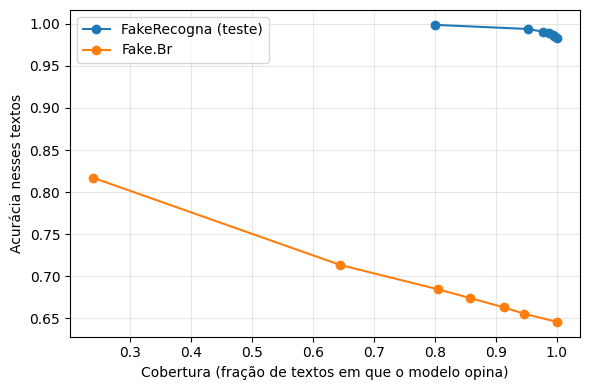

In [ ]:
# Gráfico de cobertura x acurácia (salvo em PNG no Drive).

import matplotlib.pyplot as plt
lim = (0.5, 0.7, 0.8, 0.9, 0.95, 0.99, 0.999)
a = cobertura_acuracia(df_t["y"], df_t["p"], lim); b = cobertura_acuracia(df_b["y"], df_b["p"], lim)
plt.figure(figsize=(6, 4))
plt.plot(a["cobertura"], a["acuracia"], "o-", label="FakeRecogna (teste)")
plt.plot(b["cobertura"], b["acuracia"], "o-", label="Fake.Br")
plt.xlabel("Cobertura (fração de textos em que o modelo opina)"); plt.ylabel("Acurácia nesses textos")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{PASTA}/cobertura_acuracia.png", dpi=200); plt.show()

## 7. Experimentos de fechamento
### 7a. Acurácia do BERT por fonte
Se o BERT dependesse só do domínio, ele cairia nas fontes que publicam as duas classes.

In [ ]:
# EXPERIMENTO 7a: acurácia do BERT por fonte.
# Principal: acha as fontes com as duas classes ("mistas") e compara a acurácia
# nelas com a das fontes de uma classe só. Se o BERT dependesse só do domínio,
# cairia nas fontes mistas.

t = test.reset_index(drop=True).assign(p=p_test)
t["ok"] = (t["p"] > 0.5).astype(int) == t["label"]

g = t.groupby("source")["label"].agg(["size", "mean"])
mistas = g[(g["mean"] > 0) & (g["mean"] < 1) & (g["size"] >= 30)].index
print("Fontes com as 2 classes:", list(mistas))
print("BERT nas fontes de 1 classe só:", round(t[~t.source.isin(mistas)]["ok"].mean(), 4), "| n =", (~t.source.isin(mistas)).sum())
print("BERT nas fontes com 2 classes:", round(t[t.source.isin(mistas)]["ok"].mean(), 4), "| n =", t.source.isin(mistas).sum())
print(t[t.source.isin(mistas)].groupby(["source", "label"])["ok"].agg(["size", "mean"]).round(3))

Saída obtida (24/11/2026):
```
Fontes com as 2 classes: ['g1.globo.com', 'noticias.uol.com.br']
BERT nas fontes de 1 classe só: 0.987 | n = 5633
BERT nas fontes com 2 classes: 0.9755 | n = 2287
                           size   mean
source              label
g1.globo.com        0       532  0.991
                    1       320  0.994
noticias.uol.com.br 0      1039  0.980
                    1       396  0.929
```
**Leitura:** o BERT **não depende só do domínio** (97,6% nas fontes com as duas classes). Porém, dentro de g1 e UOL, os textos "fake" são matérias das seções de checagem (Fato ou Fake, UOL Confere): o modelo ainda pode estar separando *texto de checagem* de *texto de reportagem*.

### 7b. Máscara do vocabulário de checagem (TF-IDF)
Apagamos termos típicos de agências de checagem e retreinamos. A máscara é **parcial** (lista manual de termos).

In [ ]:
# EXPERIMENTO 7b: MÁSCARA (ablação) do vocabulário de checagem.
# Principal: MASK é uma regex com termos típicos de agências (falsa, circula,
# uol confere...); mascarar() apaga esses termos; o TF-IDF é retreinado.
# Se a acurácia quase não cai, o sinal está espalhado no gênero do texto.

MASK = re.compile(r"\b(uol confere|fato ou fake|nas redes|aos fatos|e-farsas|boatos?|confere|falsa|falso|enganos[ao]|verdade|verificamos|circula\w*|facebook|whatsapp|tuíte|post\w*|publicaç\w+|lupa|comprova|none)\b")
mascarar = lambda s: s.str.replace(MASK, " ", regex=True)

tr_txt, te_txt = train["text"], test["text"]
mix = test["source"].isin(mistas).values
for nome, f in [("original", lambda s: s), ("mascarado", mascarar)]:
    v, c = treinar_tfidf(f(tr_txt), train["label"])
    ok = c.predict(v.transform(f(te_txt))) == test["label"].values
    print(f"TF-IDF {nome:9s} | geral: {ok.mean():.4f} | g1+UOL: {ok[mix].mean():.4f} | outras: {ok[~mix].mean():.4f}")

nomes = v.get_feature_names_out(); coef = c.coef_[0]
print("\nFAKE após máscara:", list(nomes[coef.argsort()[-20:][::-1]]))
print("REAL após máscara:", list(nomes[coef.argsort()[:20]]))

Saída obtida (24/11/2026):
```
TF-IDF original  | geral: 0.9542 | g1+UOL: 0.9383 | outras: 0.9606
TF-IDF mascarado | geral: 0.9491 | g1+UOL: 0.9314 | outras: 0.9563

FAKE após máscara: ['lula', 'sociais', 'vídeo', 'pra', 'compartilhamentos', 'texto', 'conteúdo', 'veja', 'pois', 'afirma', 'teria', 'mostra', 'povo', 'pelas redes', 'checou', 'você', 'no twitter', 'mensagem', 'compartilhadas', 'afirmação']
REAL após máscara: ['disse', 'hoje', 'para', 'afirmou', 'da', 'nesta', 'coronavírus', 'feira', 'do', 'os', 'em', 'ontem', 'segundo', 'de', 'que', 'pandemia', 'com', 'uol', 'escreveu', 'um']
```
**Leitura:** a máscara quase não altera a acurácia (95,4% → 94,9%). Os termos que assumem o lugar continuam sendo de **checagem** (*checou, compartilhadas, mensagem, afirmação*) contra termos de **reportagem** (*disse, afirmou, ontem, segundo*). O sinal é o **gênero textual**, distribuído pelo vocabulário, e não um punhado de palavras-chave. *coronavírus/pandemia* do lado real sugere também diferença de época entre as classes (hipótese). *lula* indica viés de assunto.

Por isso o BERT mascarado não foi executado: se a máscara não remove o sinal nem do TF-IDF, não há expectativa de que remova do BERT.

### 7c. Quase-duplicatas entre treino e teste
O mesmo boato pode ser checado por vários sites; num split aleatório, textos quase iguais podem cair no treino e no teste.

In [ ]:
# EXPERIMENTO 7c: QUASE-DUPLICATAS entre treino e teste (vazamento).
# Principal: cosseno entre vetores TF-IDF (produto escalar, pois são normalizados);
# para cada texto do teste pega o mais parecido do treino, em blocos de 500.

from sklearn.feature_extraction.text import TfidfVectorizer
v = TfidfVectorizer(min_df=2, max_features=100_000, sublinear_tf=True)
Xtr, Xte = v.fit_transform(train["text"]), v.transform(test["text"])
mx = np.zeros(Xte.shape[0])
for i in range(0, Xte.shape[0], 500):
    mx[i:i+500] = (Xte[i:i+500] @ Xtr.T).toarray().max(1)   # TF-IDF é L2-normalizado: produto = cosseno
dup = mx > 0.8
print(f"Quase-duplicatas no teste: cos>0,8 = {dup.mean():.1%} | cos>0,9 = {(mx > 0.9).mean():.1%}")
print(f"BERT nos quase-duplicados: {t['ok'][dup].mean():.4f} (n={dup.sum()}) | no resto: {t['ok'][~dup].mean():.4f} (n={(~dup).sum()})")

resultados["bert_por_fonte"] = {"fontes_mistas": list(mistas),
                                "acc_mistas": round(float(t[t.source.isin(mistas)]["ok"].mean()), 4),
                                "acc_uma_classe": round(float(t[~t.source.isin(mistas)]["ok"].mean()), 4)}
resultados["duplicatas"] = {"frac_cos08": float(dup.mean()), "acc_dup": float(t['ok'][dup].mean()),
                            "acc_sem_dup": float(t['ok'][~dup].mean())}
json.dump(resultados, open(f"{PASTA}/resultados_atalho.json", "w"), indent=2)

### 7d. Figuras: calibração, ROC, atalhos e matrizes de confusão

In [ ]:
# FIGURAS: calibração (com ECE), curvas ROC, barras dos atalhos e matrizes.
# Principal: calib() agrupa as previsões por faixa de confiança e compara com a
# acurácia real; ECE = erro médio de calibração ponderado pelo tamanho da faixa.

import os, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
os.makedirs(f"{PASTA}/figs", exist_ok=True)
R = json.load(open(f"{PASTA}/resultados_atalho.json"))
sets = {"FakeRecogna (teste)": pd.read_csv(f"{PASTA}/pred_bert_test.csv"),
        "Fake.Br": pd.read_csv(f"{PASTA}/pred_bert_br.csv")}

def calib(y, p, bins=10):
    conf, ok = np.maximum(p, 1 - p), ((p > 0.5).astype(int) == y)
    ed, rows = np.linspace(0.5, 1, bins + 1), []
    for a, b in zip(ed[:-1], ed[1:]):
        m = (conf > a) & (conf <= b)
        if m.any(): rows.append((conf[m].mean(), ok[m].mean(), m.mean()))
    r = np.array(rows); return r, float((r[:, 2] * abs(r[:, 1] - r[:, 0])).sum())   # ECE

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for nome, d in sets.items():
    y, p = d["y"].values, d["p"].values; r, e = calib(y, p)
    ax[0].plot(r[:, 0], r[:, 1], "o-", label=f"{nome} (ECE={e:.3f})")
    fpr, tpr, _ = roc_curve(y, p); ax[1].plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y, p):.3f})")
ax[0].plot([.5, 1], [.5, 1], "k--"); ax[0].set(title="Calibração", xlabel="confiança média", ylabel="acurácia"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set(title="ROC", xlabel="FPR", ylabel="TPR"); ax[1].legend()
bar = {"só URL (source_path)": R["source_path"][0], "só categoria": R["category"][0],
       "só formato da data": R["date_fmt"][0], "TF-IDF (texto)": R["tfidf_texto_completo"][0],
       "BERTimbau": R["bert"]["fr_teste"]["acc"]}
ax[2].barh(list(bar), list(bar.values())); ax[2].set(xlim=(.8, 1), title="Acurácia no teste (FakeRecogna)")
for i, v_ in enumerate(bar.values()): ax[2].text(v_ + .002, i, f"{v_:.1%}", va="center")
plt.tight_layout(); plt.savefig(f"{PASTA}/figs/calibracao_roc_atalhos.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, (nome, d) in zip(ax, sets.items()):
    cm = confusion_matrix(d["y"], (d["p"] > 0.5).astype(int)); a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, cm[i, j], ha="center", va="center")
    a.set(title=nome, xticks=[0, 1], yticks=[0, 1], xticklabels=["real", "fake"],
          yticklabels=["real", "fake"], xlabel="previsto", ylabel="verdadeiro")
plt.tight_layout(); plt.savefig(f"{PASTA}/figs/matrizes.png", dpi=200); plt.show()

## 8. Explicabilidade: oclusão e heurísticas de persuasão
**Oclusão:** remove cada palavra e mede quanto o **logit** (logit_fake − logit_real) cai. Usamos o logit porque a probabilidade satura perto de 0 e 1. Mostra o que o modelo usou, não causalidade.

**Heurísticas de persuasão:** regras (regex) **não validadas**; servem só como apoio à leitura. Observação: o BERT vê o texto em minúsculas, então "CAIXA ALTA" é avaliada no texto original e não influencia a pontuação.

In [ ]:
# EXPLICABILIDADE por OCLUSÃO.
# Principal: logit_fake() devolve logit_fake - logit_real (usa o logit porque a
# probabilidade satura perto de 0 e 1); oclusao() remove uma palavra por vez e
# mede quanto o logit cai: as que mais derrubam são as que mais pesaram.

@torch.no_grad()
def logit_fake(textos):
    enc = tok(textos, truncation=True, max_length=128, padding=True, return_tensors="pt").to(model.device)
    lg = model(**enc).logits
    return (lg[:, 1] - lg[:, 0]).float().cpu().numpy()     # positivo = empurra para "fake"

def oclusao(texto, topk=8):
    pal = texto.split()[:60]
    base = logit_fake([" ".join(pal)])[0]
    variantes = [" ".join(pal[:i] + pal[i+1:]) for i in range(len(pal))]
    imp = base - logit_fake(variantes)          # quanto o logit cai sem a palavra
    idx = np.argsort(-imp)[:topk]
    return [(pal[i], round(float(imp[i]), 2)) for i in idx]

@torch.no_grad()
def prob_fake(textos):
    return 1 / (1 + np.exp(-logit_fake(textos)))          # = softmax com 2 classes

In [ ]:
# HEURÍSTICAS DE PERSUASÃO (regras com regex, NÃO validadas): caixa alta,
# exclamações, pedido de compartilhamento, generalizações, fonte vaga.

import re
def sinais(t):
    s = []
    letras = [c for c in t if c.isalpha()]
    if (letras and sum(c.isupper() for c in letras) / len(letras) > 0.3) or \
       re.search(r"\b[A-ZÁÀÂÃÉÊÍÓÔÕÚÇ]{4,}\b", t):
        s.append("CAIXA ALTA")
    if t.count("!") >= 3: s.append("muitas exclamações")
    if re.search(r"\b(urgente|compartilhe|repasse|antes que (apaguem|removam))\b", t, re.I): s.append("urgência / pedido de compartilhamento")
    if re.search(r"\b(sempre|nunca|todos|ninguém|100%)\b", t, re.I): s.append("generalização absoluta")
    if re.search(r"(segundo fontes|um amigo|alguém me contou|fonte (anônima|próxima))", t, re.I): s.append("fonte anônima/vaga")
    return s

In [ ]:
# Exemplo: oclusão e heurísticas num texto sensacionalista e numa nota sóbria.

exemplo = "URGENTE!!! Compartilhe antes que apaguem: governo vai confiscar a poupança de todos!"
t = exemplo.lower()
print(oclusao(t))
print(sinais(exemplo))

exemplo2 = "O Ministério da Saúde informou nesta segunda-feira que a campanha de vacinação contra a gripe será ampliada para novos grupos a partir do próximo mês."
print(round(float(prob_fake([exemplo2.lower()])[0]), 3), oclusao(exemplo2.lower()), sinais(exemplo2))  # texto ORIGINAL, para ver a caixa alta

[('compartilhe', 0.36), ('urgente!!!', 0.34), ('que', 0.05), ('confiscar', 0.04), ('antes', 0.02), ('a', 0.01), ('de', -0.0), ('vai', -0.04)]
['CAIXA ALTA', 'muitas exclamações', 'urgência / pedido de compartilhamento', 'generalização absoluta']
0.001 [('vacinação', 0.15), ('que', 0.06), ('a', 0.05), ('ampliada', 0.04), ('novos', 0.03), ('campanha', 0.02), ('partir', 0.0), ('para', -0.01)] []


## 9. RAG: índice do FACTCK.BR e calibração do limiar
Cada alegação checada (`claimReviewed`) vira um vetor de 384 dimensões com o `multilingual-e5-small` (prefixo `passage:`); a consulta usa o prefixo `query:`. A similaridade é o cosseno (produto escalar de vetores normalizados).

In [ ]:
# RAG, parte 1: ÍNDICE do FACTCK.BR.
# Principal: SentenceTransformer("multilingual-e5-small").encode() transforma
# cada alegação em um embedding de 384 dimensões (prefixo "passage:");
# normalize_embeddings=True permite usar o produto escalar como cosseno.
# scores(texto) codifica a consulta ("query:") e compara com todas as alegações.

from sentence_transformers import SentenceTransformer
emb = SentenceTransformer("intfloat/multilingual-e5-small")

fc = pd.read_csv("FACTCK.BR/FACTCKBR.tsv", sep="\t")
fc = fc.dropna(subset=["claimReviewed"]).reset_index(drop=True)
fc["veredito"] = fc["alternativeName"].astype(str).str.strip().str.lower()

E = emb.encode(["passage: " + t for t in fc["claimReviewed"].tolist()],
               normalize_embeddings=True, batch_size=64, show_progress_bar=True)
np.save(f"{PASTA}/E_factck_alegacao.npy", E)
fc.to_csv(f"{PASTA}/factck_limpo.csv", index=False)
print(E.shape, len(fc))      # (1300, 384) 1300

def scores(texto):
    q = emb.encode(["query: " + texto], normalize_embeddings=True)[0]
    return E @ q

**Calibração do limiar.** 30 alegações sorteadas (`random_state=7`) receberam uma paráfrase cada (positivos), e 15 frases não correspondem a nenhuma alegação (negativos; 5 sem relação e 10 de assunto parecido).

> **Transparência:** as 30 paráfrases foram **rascunhadas por um LLM e usadas sem edição**. O mesmo conjunto foi usado para escolher e para reportar o limiar (não há separação dev/teste), então os números abaixo são otimistas.

**Ablação do índice:** um índice com *alegação + título* teve desempenho pior (top-1 76,7%; maior score de negativo 0,900) do que o índice só com a alegação (top-1 86,7%). Ficamos com o índice só da alegação.

In [ ]:
# RAG, parte 2: CALIBRAÇÃO DO LIMIAR.
# casam = 30 paráfrases de alegações conhecidas (positivos; rascunhadas por LLM);
# nao_casam = 15 frases que não correspondem a nenhuma alegação (negativos).
# Mede em que posição a alegação certa aparece (top-1, top-3) e varre limiares
# para equilibrar "acha a certa" x "falso casamento".

# índice da alegação no FACTCK : paráfrase (rascunhada por LLM)
casam = {
    347:  "A Polícia Federal teria encontrado uma ilha de quatro milhões de reais pertencente à família do Lula.",
    1160: "Circula um alerta dizendo que a dipirona S-500 trazida da Venezuela vem contaminada com um vírus perigoso e que ninguém deve tomar.",
    374:  "Uma pesquisa do Paraná Pesquisas, supostamente registrada no TSE, mostraria o Bolsonaro vencendo em todos os estados.",
    361:  "Um vídeo afirma que houve fraude na eleição presidencial de 2014.",
    1215: "Circula uma imagem que mostraria Jesus como travesti.",
    500:  "Enquanto todo mundo assiste à Copa, os deputados estariam articulando a criação de 400 novos municípios.",
    1284: "Mensagem diz que o general Villas Bôas anunciou uma intervenção militar e chamou a população para participar.",
    790:  "Comparação diz que a pensão por morte, hoje de 100% do salário, cairia para 50% mais 10% por dependente com a reforma da Previdência.",
    34:   "Imagem mostra grevistas parados no celular enquanto os outros trabalhadores seguem para o serviço.",
    825:  "Dizem que o general Augusto Heleno pediu a prisão do jornalista Paulo Henrique Amorim, da Record, por ameaça de morte ao presidente Bolsonaro.",
    956:  "Vídeo gravado por uma câmera dentro de um carro teria flagrado o instante exato da queda do Boeing 737 MAX 8 na Etiópia.",
    830:  "Alerta diz para não tomar o paracetamol com a marca P-500, que médicos teriam provado conter o vírus Machupo.",
    618:  "Segundo um vazamento do WikiLeaks, a Globo teria repassado à Unesco só 10% do dinheiro arrecadado no Criança Esperança.",
    1159: "Apreenderam seis mil toras de mogno, no valor de 8 milhões de reais, e o dono seria o marido da Marina, apontado como um dos maiores desmatadores da Amazônia.",
    528:  "Afirma-se que Pedro Parente estava no Banco Central durante a hiperinflação do governo Sarney.",
    1256: "Mensagem de campanha da Marina Silva, candidata número 17, pedindo que o país não desista.",
    164:  "Dizem que a mãe e a irmã do Adélio trabalhavam no gabinete da deputada Maria do Rosário, e que a imprensa de esquerda não comenta isso.",
    51:   "Balanço dos protestos do dia diria que só 1% defendia a educação e que 90% estavam ali por Lula livre.",
    534:  "Um político afirma que terminou seus mandatos com 87% de aprovação popular.",
    237:  "Alerta aos eleitores: tirar foto do comprovante de votação seria crime eleitoral.",
    731:  "Imagens da internet mostrariam a Funai, com apoio da Força Nacional armada, entrando em fazendas para colocar indígenas dentro delas.",
    152:  "Mensagem urgente diz que a China mandou um recado aos EUA e ao mundo para se prepararem para uma Terceira Guerra Mundial.",
    113:  "Notícia diz que o Exército perfurou um poço em Caicó, no Nordeste, e achou água jorrando num terreno onde hoje funciona um complexo de creches.",
    1063: "Circula que o filho do Lula tem uma fazenda avaliada em 50 milhões de reais.",
    725:  "Alguém afirma que as drogas causam 90% dos crimes violentos do país.",
    253:  "Dizem que o Ciro Gomes voltou da Europa e declarou voto no Bolsonaro.",
    598:  "Compara-se que os tiroteios em massa mataram cerca de 300 pessoas nos EUA em 2017, enquanto no Brasil morrem em média 120 pessoas por dia baleadas.",
    928:  "Alguém teria transferido os chefes das maiores facções criminosas para presídios de segurança máxima.",
    351:  "O papa teria mandado um terço para o Lula, que estaria preso há 67 dias.",
    804:  "Em meio a ataques na Câmara, o Moro teria dito que, se falasse a verdade, teria de prender todo mundo e fechar o Congresso.",
}

nao_casam = [
    # sem relação nenhuma
    "Receita de pão de queijo com polvilho azedo.",
    "O time venceu a partida de ontem por três a um.",
    "A previsão do tempo indica sol e temperatura alta durante a semana.",
    "Como trocar o pneu do carro em poucos passos.",
    "A biblioteca da universidade amplia o horário de funcionamento nas provas.",
    # difíceis: mesmo assunto de alguma alegação, mas não é nenhuma delas
    "A Polícia Federal fez uma operação nesta manhã contra fraudes em licitações em três estados.",
    "O TSE lançou um aplicativo para o eleitor consultar o local de votação.",
    "A Anvisa publicou uma nota explicando como descartar medicamentos vencidos.",
    "A Câmara aprovou um projeto que muda as regras de repasse de verbas aos municípios.",
    "O governo enviou ao Congresso o texto de uma reforma da Previdência, que ainda será debatido.",
    "O Inpe divulgou os dados mensais de desmatamento na Amazônia.",
    "A Boeing informou que está revisando os procedimentos de segurança de seus aviões.",
    "O Exército distribui água em carros-pipa para cidades do semiárido nordestino.",
    "Representantes da Funai participaram de uma audiência pública sobre demarcação de terras.",
    "A Unesco divulgou um relatório sobre a educação no Brasil.",
]

# positivos: a checagem certa aparece no top-k? com que score?
rows = []
for idx, t in casam.items():
    s = scores(t)
    ordem = np.argsort(-s)
    rows.append({"idx": idx, "score_certa": round(float(s[idx]), 3),
                 "posicao": int(np.where(ordem == idx)[0][0]) + 1,
                 "top1_score": round(float(s.max()), 3)})
pos = pd.DataFrame(rows)
print(pos)
print("top-1:", (pos.posicao == 1).mean(), "| top-3:", (pos.posicao <= 3).mean())

# negativos: maior score que qualquer checagem recebeu
neg = [float(scores(t).max()) for t in nao_casam]
print("\nnegativos (maior score):", [round(x, 3) for x in neg])

# varredura de limiar
print("\nlimiar | acha a certa (positivos) | falso casamento (negativos)")
for lim in np.arange(0.70, 0.95, 0.02):
    acha = (pos.score_certa >= lim).mean()
    falso = np.mean([x >= lim for x in neg])
    print(f"{lim:.2f}   | {acha:.0%}                    | {falso:.0%}")

     idx  score_certa  posicao  top1_score
0    347        0.924        1       0.924
1   1160        0.920        1       0.920
2    374        0.913        2       0.930
3    361        0.936        1       0.936
4   1215        0.928        1       0.928
5    500        0.934        1       0.934
6   1284        0.920        1       0.920
7    790        0.884        1       0.884
8     34        0.920        1       0.920
9    825        0.941        1       0.941
10   956        0.944        1       0.944
11   830        0.939        1       0.939
12   618        0.937        2       0.942
13  1159        0.920        1       0.920
14   528        0.953        1       0.953
15  1256        0.897        1       0.897
16   164        0.925        1       0.925
17    51        0.884        2       0.893
18   534        0.929        1       0.929
19   237        0.919        1       0.919
20   731        0.937        1       0.937
21   152        0.929        1       0.929
22   113   

Com limiar **0,90**: acha a checagem certa em 87% dos positivos e 0% de falso casamento nos 15 negativos. Os scores do e5 são comprimidos (negativos 0,851–0,887; positivos 0,884–0,953), então a margem é pequena e só o ranking é confiável.

**Falso casamento com 100 notícias reais do teste** (amostra maior de negativos, com IC exato):

In [ ]:
# RAG, parte 3: falso casamento com 100 notícias REAIS do teste.
# Principal: beta.ppf() dá o intervalo de confiança exato (Clopper-Pearson)
# para uma proporção com amostra pequena. Salva a configuração do RAG no Drive.

from scipy.stats import beta
neg_reais = test[test.label == 0].sample(100, random_state=0)["text"].str[:300].tolist()
sc = (emb.encode(["query: " + x for x in neg_reais], normalize_embeddings=True) @ E.T).max(1)
k, n = int((sc >= 0.90).sum()), len(sc)
lo = 0.0 if k == 0 else beta.ppf(0.025, k, n - k + 1)
hi = beta.ppf(0.975, k + 1, n - k)
print(f"RAG: {k}/{n} notícias reais passaram do limiar 0,90 ({k/n:.0%}, IC95% {lo:.0%}–{hi:.0%})")
print("Percentis 50/95/100 do maior score:", np.percentile(sc, [50, 95, 100]).round(3))
for x, s in sorted(zip(neg_reais, sc), key=lambda z: -z[1])[:3]:
    print(f"  {s:.3f} | {x[:120]}")

LIMIAR = 0.90
json.dump({"limiar": LIMIAR, "indice": "so_alegacao", "n_positivos": len(pos), "n_negativos": len(neg),
           "top1": round(float((pos.posicao == 1).mean()), 3), "top3": round(float((pos.posicao <= 3).mean()), 3),
           "faixa_negativos": [round(min(neg), 3), round(max(neg), 3)],
           "faixa_positivos": [round(float(pos.score_certa.min()), 3), round(float(pos.score_certa.max()), 3)],
           "negativos_reais_100": {"falsos": k, "n": n, "ic95": [float(lo), float(hi)]}},
          open(f"{PASTA}/rag_config.json", "w"), indent=2)

## Conclusão
Em split aleatório do FakeRecogna 2.0, um modelo que só vê o endereço da URL acerta 99,2%, estatisticamente acima do BERTimbau (98,4%; McNemar p<0,001). Fora desse conjunto (Fake.Br), o BERT cai para 64,6% (IC95% 63,4–65,8) e fica superconfiante. O modelo não depende só do domínio (97,6% nos sites com as duas classes), mas nesse dataset os textos "fake" são artigos de checagem e os "reais" são reportagens; esse sinal de gênero está espalhado no vocabulário e resiste à remoção das palavras de checagem.
**Logo, os ~98% medem a distinção entre gêneros textuais (checagem × notícia), não a detecção de desinformação.** Os testes mostram correlação; não provam o que o BERT usa internamente.